# Chapter 6: Fuzzy Systems

This notebook collects the runnable examples of *Chapter 6: Fuzzy Systems* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.

## Learning objectives

After working through this notebook you should be able to:

- explain the difference between random and conceptual uncertainty.
- compare classical and fuzzy sets and their characteristic and membership functions.
- compute the support, core, height, and alpha-cut.
- define common membership functions and design linguistic variables.
- apply the fuzzy union, intersection, and complement operators.
- design and implement Mamdani and Sugeno fuzzy inference systems.


In [1]:
%matplotlib inline

## Example 6.1: Classical sets and the characteristic function in Python

Script version: `example_6_1.py`

In [2]:
# Example 6.1: Classical (crisp) sets and the characteristic function in Python
A = {1, 2, 3, 4, 5}
 
def indicator(x, S):
    """I_A(x) = 1 if x ∈ A else 0"""
    return 1 if x in S else 0
 
for x in (1, 2, 6):
    print(f"{x} ∈ A ? {x in A}  ->  I_A({x}) = {indicator(x, A)}")
 
vowels = {"a", "e", "i", "o", "u"}
print("'y' ∈ V ?", "y" in vowels, " <- classical logic forces a yes/no answer")

1 ∈ A ? True  ->  I_A(1) = 1
2 ∈ A ? True  ->  I_A(2) = 1
6 ∈ A ? False  ->  I_A(6) = 0
'y' ∈ V ? False  <- classical logic forces a yes/no answer


## Example 6.2: Discrete fuzzy sets and basic concepts

Script version: `example_6_2.py`

In [3]:
# Example 6.2: Discrete fuzzy sets — each member with a degree of membership
# "Even days" of the Iranian week (Saturday, Monday, Wednesday); Friday is a holiday: partly even?
even_days = {"Saturday": 1.0, "Monday": 1.0, "Wednesday": 1.0, "Friday": 0.5}
# "Natural numbers close to 1"
near_one = {1: 1.0, 2: 0.5, 3: 0.25, 4: 0.1}
 
def mu(fuzzy_set, x):
    return fuzzy_set.get(x, 0.0)          # elements not listed have membership 0
 
print("μ_even(Monday)   =", mu(even_days, "Monday"))
print("μ_even(Friday)   =", mu(even_days, "Friday"))
print("μ_even(Tuesday)  =", mu(even_days, "Tuesday"))
print("μ_near_one(3)    =", mu(near_one, 3), "| μ_near_one(7) =", mu(near_one, 7))
 
support = [x for x, m in near_one.items() if m > 0]
core = [x for x, m in near_one.items() if m == 1]
print("support(near_one) =", support, "| core =", core, "| height =", max(near_one.values()))
for alpha in (0.2, 0.5):
    print(f"alpha-cut at {alpha}:", [x for x, m in near_one.items() if m >= alpha])
print("cardinality |near_one| =", sum(near_one.values()))

μ_even(Monday)   = 1.0
μ_even(Friday)   = 0.5
μ_even(Tuesday)  = 0.0
μ_near_one(3)    = 0.25 | μ_near_one(7) = 0.0
support(near_one) = [1, 2, 3, 4] | core = [1] | height = 1.0
alpha-cut at 0.2: [1, 2, 3]
alpha-cut at 0.5: [1, 2]
cardinality |near_one| = 1.85


## Example 6.3: Five types of membership functions for "numbers close to 1"

Script version: `example_6_3.py`

Triangular (0.5, 1, 1.5)       μ(1.2) = 0.600
Trapezoidal (0, 0.7, 1.3, 2)   μ(1.2) = 1.000
Gaussian (c=1, σ=0.4)          μ(1.2) = 0.882
Generalized bell (0.5, 2, 1)   μ(1.2) = 0.975
Sigmoid (a=6, c=1)             μ(1.2) = 0.769


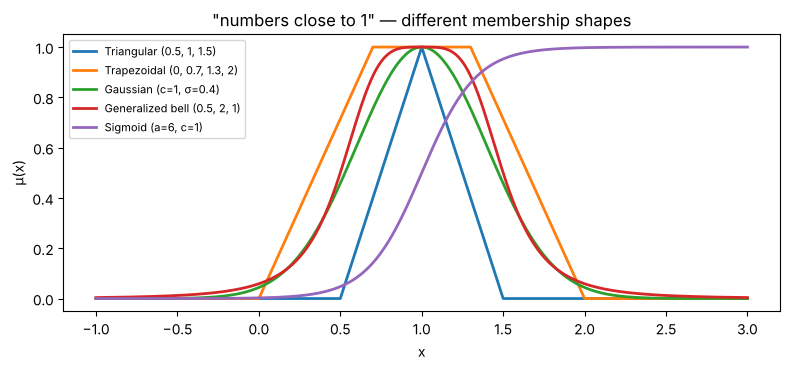

In [4]:
# Example 6.3: Continuous membership functions — triangular, trapezoidal, Gaussian, bell, and sigmoidal
import numpy as np
import matplotlib.pyplot as plt
 
def trimf(x, a, b, c):     return np.maximum(np.minimum((x - a) / (b - a), (c - x) / (c - b)), 0)
def trapmf(x, a, b, c, d): return np.maximum(np.minimum.reduce([(x - a) / (b - a), np.ones_like(x), (d - x) / (d - c)]), 0)
def gaussmf(x, c, s):      return np.exp(-((x - c) ** 2) / (2 * s ** 2))
def gbellmf(x, a, b, c):   return 1 / (1 + np.abs((x - c) / a) ** (2 * b))
def sigmf(x, a, c):        return 1 / (1 + np.exp(-a * (x - c)))
 
x = np.linspace(-1, 3, 401)
mfs = {"Triangular (0.5, 1, 1.5)": trimf(x, 0.5, 1, 1.5),
       "Trapezoidal (0, 0.7, 1.3, 2)": trapmf(x, 0, 0.7, 1.3, 2),
       "Gaussian (c=1, σ=0.4)": gaussmf(x, 1, 0.4),
       "Generalized bell (0.5, 2, 1)": gbellmf(x, 0.5, 2, 1),
       "Sigmoid (a=6, c=1)": sigmf(x, 6, 1)}
for name, m in mfs.items():
    print(f"{name:<30} μ(1.2) = {np.interp(1.2, x, m):.3f}")
 
plt.figure(figsize=(8, 3.8))
for name, m in mfs.items(): plt.plot(x, m, lw=2, label=name)
plt.xlabel("x"); plt.ylabel("μ(x)"); plt.title('"numbers close to 1" — different membership shapes')
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("fig6_1.png", dpi=300)

## Example 6.4: The fuzzy set "tall" from three perspectives and the linguistic variable "height"

Script version: `example_6_4.py`

μ_tall(175) from view 1 (children)    = 0.99
μ_tall(175) from view 2 (general)     = 0.80
μ_tall(175) from view 3 (basketball)  = 0.00
height 150 cm -> short=0.97, medium=0.03, tall=0.00
height 165 cm -> short=0.04, medium=0.96, tall=0.00
height 175 cm -> short=0.00, medium=0.79, tall=0.21
height 185 cm -> short=0.00, medium=0.04, tall=0.96


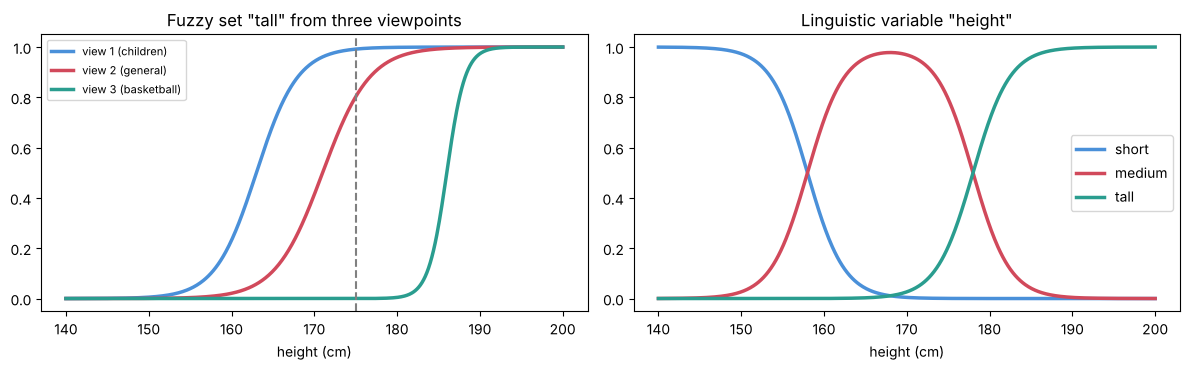

In [5]:
# Example 6.4: The fuzzy set "tall" from three perspectives, and the linguistic variable "height"
import numpy as np
import matplotlib.pyplot as plt
 
sig = lambda x, a, c: 1 / (1 + np.exp(-a * (x - c)))
h = np.linspace(140, 200, 601)
 
# Part 1: "tall" is context dependent (three different observers / populations)
tall_views = {"view 1 (children)": sig(h, 0.4, 163), "view 2 (general)": sig(h, 0.35, 171),
              "view 3 (basketball)": sig(h, 0.9, 186)}
i175 = np.argmin(abs(h - 175))
for name, m in tall_views.items():
    print(f"μ_tall(175) from {name:<20} = {m[i175]:.2f}")
 
# Part 2: linguistic variable "height" with three terms
short = 1 - sig(h, 0.45, 158)
medium = sig(h, 0.45, 158) * (1 - sig(h, 0.45, 178))
tall = sig(h, 0.45, 178)
for x in (150, 165, 175, 185):
    i = np.argmin(abs(h - x))
    print(f"height {x} cm -> short={short[i]:.2f}, medium={medium[i]:.2f}, tall={tall[i]:.2f}")
 
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for (n, m), c in zip(tall_views.items(), ["#4a90d9", "#d1495b", "#2a9d8f"]):
    ax[0].plot(h, m, lw=2.5, c=c, label=n)
ax[0].axvline(175, ls="--", c="gray"); ax[0].set_title('Fuzzy set "tall" from three viewpoints')
ax[0].set_xlabel("height (cm)"); ax[0].legend(fontsize=8)
for m, n, c in [(short, "short", "#4a90d9"), (medium, "medium", "#d1495b"), (tall, "tall", "#2a9d8f")]:
    ax[1].plot(h, m, lw=2.5, c=c, label=n)
ax[1].set_title('Linguistic variable "height"'); ax[1].set_xlabel("height (cm)"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig6_2.png", dpi=300)

## Example 6.5: Union, intersection, and complement operators on the sets "normal temperature" and "fever"

Script version: `example_6_5.py`

At 37.5°C: μ_normal=0.50, μ_fever=0.33
  union (max)=0.50, intersection (min)=0.33, product=0.17, not fever=0.67
Law of excluded middle fails: max(μ, 1-μ) = 0.67


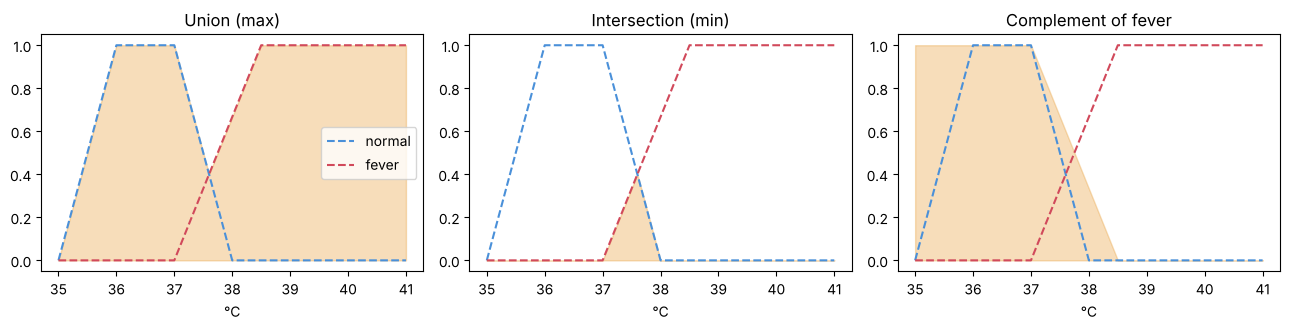

In [6]:
# Example 6.5: Fuzzy operators — union, intersection, and complement
import numpy as np
import matplotlib.pyplot as plt
 
x = np.linspace(35, 41, 601)                        # body temperature (°C)
normal = np.clip((38 - x) / 1.0, 0, 1) * (x >= 36) + (x < 36) * np.clip((x - 35) / 1.0, 0, 1)
fever = np.clip((x - 37) / 1.5, 0, 1)
 
union = np.maximum(normal, fever)                   # A ∪ B : max
inter = np.minimum(normal, fever)                   # A ∩ B : min
not_fever = 1 - fever                               # ¬B    : 1 - μ
prod = normal * fever                               # algebraic product (another t-norm)
 
t = 37.5; i = np.argmin(abs(x - t))
print(f"At {t}°C: μ_normal={normal[i]:.2f}, μ_fever={fever[i]:.2f}")
print(f"  union (max)={union[i]:.2f}, intersection (min)={inter[i]:.2f}, "
      f"product={prod[i]:.2f}, not fever={not_fever[i]:.2f}")
print("Law of excluded middle fails: max(μ, 1-μ) =", round(max(fever[i], 1 - fever[i]), 2))
 
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, (title, curve) in zip(ax, [("Union (max)", union), ("Intersection (min)", inter), ("Complement of fever", not_fever)]):
    a.plot(x, normal, "--", c="#4a90d9", label="normal"); a.plot(x, fever, "--", c="#d1495b", label="fever")
    a.fill_between(x, curve, alpha=0.35, color="#e9a03b"); a.set_title(title); a.set_xlabel("°C")
ax[0].legend(); plt.tight_layout(); plt.savefig("fig6_3.png", dpi=300)

## Example 6.6: A Mamdani fuzzy inference system for assessing patient risk

Script version: `example_6_6.py`

Patient: temp=36.8°C, heart rate=72 bpm
  rule: temp=normal AND hr=normal -> risk=low    | firing strength = 0.91
  => crisp risk score = 15.2

Patient: temp=37.8°C, heart rate=95 bpm
  rule: temp=normal AND hr=normal -> risk=low    | firing strength = 0.17
  rule: temp=normal AND hr=high   -> risk=medium | firing strength = 0.17
  rule: temp=fever  AND hr=normal -> risk=medium | firing strength = 0.20
  rule: temp=fever  AND hr=high   -> risk=high   | firing strength = 0.22
  => crisp risk score = 53.0

Patient: temp=39.5°C, heart rate=140 bpm
  rule: temp=fever  AND hr=high   -> risk=high   | firing strength = 0.80
  => crisp risk score = 84.4



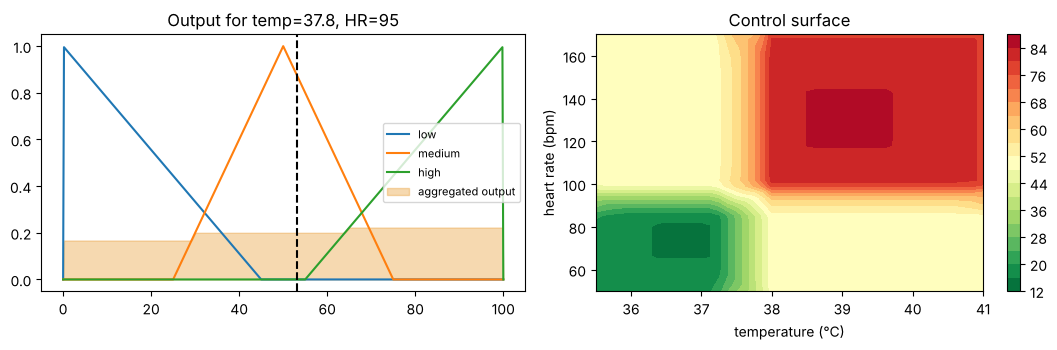

In [7]:
# Example 6.6: A Mamdani fuzzy inference system from scratch — estimating a patient's risk level
# Inputs: body temperature (°C) and heart rate (bpm) -> Output: risk score 0..100
import numpy as np
import matplotlib.pyplot as plt
 
def trimf(x, a, b, c):
    return np.maximum(np.minimum((x - a) / (b - a + 1e-9), (c - x) / (c - b + 1e-9)), 0)
 
temp_mf = {"normal": lambda t: trimf(t, 35, 36.8, 38.0), "fever": lambda t: trimf(t, 37.2, 39, 41.5)}
hr_mf = {"normal": lambda h: trimf(h, 40, 75, 100), "high": lambda h: trimf(h, 85, 130, 180)}
risk = np.linspace(0, 100, 501)
risk_mf = {"low": trimf(risk, 0, 0, 45), "medium": trimf(risk, 25, 50, 75), "high": trimf(risk, 55, 100, 100)}
 
rules = [  # IF temp is A AND heart rate is B THEN risk is C
    ("normal", "normal", "low"),
    ("normal", "high", "medium"),
    ("fever", "normal", "medium"),
    ("fever", "high", "high"),
]
 
def infer(t, h, verbose=False):
    aggregated = np.zeros_like(risk)
    for tA, hB, out in rules:
        strength = min(temp_mf[tA](t), hr_mf[hB](h))                     # AND = min (fuzzification + rule firing)
        aggregated = np.maximum(aggregated, np.minimum(strength, risk_mf[out]))  # implication + aggregation
        if verbose and strength > 0:
            print(f"  rule: temp={tA:<6} AND hr={hB:<6} -> risk={out:<6} | firing strength = {strength:.2f}")
    if aggregated.sum() == 0: return 0.0, aggregated
    return (risk * aggregated).sum() / aggregated.sum(), aggregated     # centroid defuzzification
 
for t, h in [(36.8, 72), (37.8, 95), (39.5, 140)]:
    print(f"Patient: temp={t}°C, heart rate={h} bpm")
    score, agg = infer(t, h, verbose=True)
    print(f"  => crisp risk score = {score:.1f}\n")
 
_, agg = infer(37.8, 95)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for n, m in risk_mf.items(): ax[0].plot(risk, m, label=n)
ax[0].fill_between(risk, agg, alpha=0.4, color="#e9a03b", label="aggregated output")
ax[0].axvline(infer(37.8, 95)[0], c="k", ls="--"); ax[0].legend(fontsize=8); ax[0].set_title("Output for temp=37.8, HR=95")
T, H = np.meshgrid(np.linspace(35.5, 41, 45), np.linspace(50, 170, 45))
S = np.vectorize(lambda a, b: infer(a, b)[0])(T, H)
c = ax[1].contourf(T, H, S, levels=20, cmap="RdYlGn_r"); plt.colorbar(c, ax=ax[1])
ax[1].set_xlabel("temperature (°C)"); ax[1].set_ylabel("heart rate (bpm)"); ax[1].set_title("Control surface")
plt.tight_layout(); plt.savefig("fig6_4.png", dpi=300)

## Example 6.7: A Sugeno fuzzy system with three rules

Script version: `example_6_7.py`

In [8]:
# Example 6.7: A Sugeno (TSK) fuzzy system — the output of each rule is a linear function
import numpy as np
 
def gauss(x, c, s): return np.exp(-((x - c) ** 2) / (2 * s ** 2))
 
# input: blood glucose (mg/dL) -> output: suggested insulin units (illustrative only!)
rules = [  # (membership center, width, linear consequent p*x + r)
    (100, 25, (0.00, 0.0)),     # IF glucose is normal THEN dose = 0
    (180, 35, (0.04, -4.0)),    # IF glucose is high   THEN dose = 0.04 x - 4
    (280, 45, (0.06, -6.0)),    # IF glucose is very high THEN dose = 0.06 x - 6
]
def sugeno(x):
    w = np.array([gauss(x, c, s) for c, s, _ in rules])
    f = np.array([p * x + r for _, _, (p, r) in rules])
    y = (w * f).sum() / w.sum()
    return max(y, 0.0), w / w.sum()          # a dose can not be negative
 
for g in (90, 150, 220, 300):
    y, wn = sugeno(g)
    print(f"glucose={g:>3} -> normalized weights {wn.round(2)} -> output = {y:.2f}")

glucose= 90 -> normalized weights [0.96 0.04 0.  ] -> output = 0.00
glucose=150 -> normalized weights [0.16 0.82 0.02] -> output = 1.70
glucose=220 -> normalized weights [0.   0.56 0.44] -> output = 5.86
glucose=300 -> normalized weights [0. 0. 1.] -> output = 11.99


## Example 6.8: Fuzzy C-Means clustering from scratch

Script version: `example_6_8.py`

In [9]:
# Example 6.8: Fuzzy C-Means clustering — each point belongs to all clusters to some degree
import numpy as np
from sklearn.datasets import make_blobs
 
X, _ = make_blobs(n_samples=150, centers=[(0, 0), (4, 4)], cluster_std=1.2, random_state=3)
c, m, rng = 2, 2.0, np.random.default_rng(0)
U = rng.dirichlet(np.ones(c), size=len(X))          # random initial memberships (rows sum to 1)
for it in range(100):
    Um = U ** m
    centers = (Um.T @ X) / Um.sum(0)[:, None]
    d = np.linalg.norm(X[:, None] - centers[None], axis=2) + 1e-9
    U_new = 1 / ((d[:, :, None] / d[:, None, :]) ** (2 / (m - 1))).sum(2)
    if np.abs(U_new - U).max() < 1e-5: break
    U = U_new
print("Converged after", it + 1, "iterations")
print("Centers:\n", centers.round(2))
mid = np.argmin(np.abs(U[:, 0] - 0.5))
print("A point between the two clusters:", X[mid].round(2), "-> memberships", U[mid].round(2))
print("A typical point:", X[0].round(2), "-> memberships", U[0].round(2))

Converged after 10 iterations
Centers:
 [[ 4.23  4.2 ]
 [-0.16 -0.03]]
A point between the two clusters: [1.56 2.85] -> memberships [0.56 0.44]
A typical point: [2.53 4.07] -> memberships [0.89 0.11]


## Example 6.9: Fuzzy diagnosis with max-min composition (Sanchez's method)

Script version: `example_6_9.py`

In [10]:
# Example 6.9: Fuzzy relations and max-min composition — medical diagnosis using Sanchez's method
import numpy as np
 
symptoms = ["fever", "cough", "headache", "chest pain"]
diseases = ["common cold", "influenza", "pneumonia"]
# R: how strongly each symptom is associated with each disease (expert knowledge, illustrative)
R = np.array([[0.4, 0.9, 0.8],     # fever
              [0.8, 0.7, 0.9],     # cough
              [0.5, 0.8, 0.3],     # headache
              [0.1, 0.2, 0.9]])    # chest pain
 
patients = {"patient A": [0.3, 0.9, 0.4, 0.0], "patient B": [0.9, 0.6, 0.9, 0.1], "patient C": [0.8, 0.9, 0.2, 0.8]}
for name, s in patients.items():
    s = np.array(s)
    d = np.max(np.minimum(s[:, None], R), axis=0)        # max-min composition:  D = S o R
    best = diseases[int(np.argmax(d))]
    print(f"{name}: symptoms={s} -> disease memberships {', '.join(f'{n}={v:.1f}' for n, v in zip(diseases, d))} -> {best}")

patient A: symptoms=[0.3 0.9 0.4 0. ] -> disease memberships common cold=0.8, influenza=0.7, pneumonia=0.9 -> pneumonia
patient B: symptoms=[0.9 0.6 0.9 0.1] -> disease memberships common cold=0.6, influenza=0.9, pneumonia=0.8 -> influenza
patient C: symptoms=[0.8 0.9 0.2 0.8] -> disease memberships common cold=0.8, influenza=0.8, pneumonia=0.9 -> pneumonia
